# torch.nn Linear Regression Example

## Setup

In [1]:
import random

import matplotlib.pyplot as plt
import seaborn as sns
from numpy.typing import NDArray

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

def setup() -> tuple[torch.Generator, int]:
    if torch.backends.mps.is_available():
        device = torch.device("mps")
        torch.set_default_device(device)
        generator = torch.Generator(device=device)
        print("MPS device found!")
    else:
        device = torch.device("cpu")
        generator = torch.Generator(device=device)
        print("Defaulting to CPU!")

    SEED = random.SystemRandom().randint(0, 2**32 - 1)
    torch.manual_seed(SEED)
    print(f"Random seed: {SEED}")
    return generator, SEED

def to_numpy(tensor: torch.Tensor) -> NDArray:
    return tensor.detach().cpu().numpy().squeeze()

generator, SEED = setup()

MPS device found!
Random seed: 492730890


# Minibatch Updates

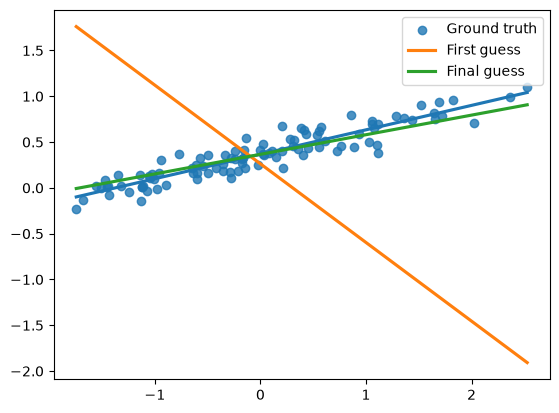

In [2]:
fig, ax = plt.subplots()

def add_to_plot(X: torch.Tensor, Y: torch.Tensor, label: str, isShowMarkers: bool = True):
    sns.regplot(
        x=to_numpy(X),
        y=to_numpy(Y),
        ax=ax,
        ci=None,
        scatter=isShowMarkers,
        label=label
    )

class LinearRegressionModel(nn.Module):
    """ Define the layers """
    def __init__(self, in_features, out_features) -> None:
        super().__init__()

        self.linear_layer = nn.Linear(in_features, out_features)

    """ Connect the layers in the forward pass """
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear_layer(x)


def get_training_set(N: int, batch_size: int, D_x: int, D_y: int):
    X = torch.randn(N, D_x)
    model_true = LinearRegressionModel(in_features=D_x,out_features=D_y)
    with torch.no_grad():
        y_true: torch.Tensor = model_true(X) + 0.1*torch.randn(N, D_y)

    add_to_plot(X, y_true, "Ground truth")

    train_dataset = TensorDataset(X, y_true)
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )
    return train_loader


learning_rate, epochs = 0.01, 20
N, batch_size = 100, 10
D_x, D_y = 1, 1

train_loader = get_training_set(N, batch_size, D_x, D_y)

# Model
model: nn.Module = LinearRegressionModel(in_features=D_x,out_features=D_y)
loss_fn = nn.MSELoss(reduction='sum')
optimiser = optim.Adam(params=model.parameters(), lr=learning_rate)

X_all: torch.Tensor = train_loader.dataset.tensors[0]
add_to_plot(X_all, model(X_all), "First guess", False)

# Optimise
for epoch in range(epochs):
    for X_batch, y_batch in train_loader:
        optimiser.zero_grad()

        y_pred = model(X_batch)
        loss: torch.Tensor = loss_fn(y_pred, y_batch)

        loss.backward()
        optimiser.step()


add_to_plot(X_all, model(X_all), "Final guess", False)

ax.legend()
plt.show()
